# Eleições 2026 — 2º turno para Presidente (25/10/2026)

Notebook reprodutível, feito a partir dos dados abertos do TSE, que responde:

1. Quantas pessoas votaram entre 17h e 19h no domingo?
2. Qual foi a proporção dos votos de 17h até 19h?
3. Quantas pessoas votaram sem biometria?
4. Qual foi a proporção dos votos sem biometria?
5. Qual foi a proporção dos votos no total e por estado (candidatos, brancos, nulos etc.)?
6. Ranking dos números digitados na hora de anular o voto.

O **resumo com uma resposta por pergunta** está no final.

### Fontes

| Pergunta | Dado | Pacote no Portal de Dados Abertos do TSE | Preparado por |
|---|---|---|---|
| 1, 2 | Log de cada urna (hora de cada voto) | `resultados-2026-arquivos-transmitidos-para-totalizacao` | `scripts/process_urna.py` |
| 3, 4 | Log de cada urna + Boletim de Urna (CSV) | idem + `resultados-2026-boletim-de-urna` | `process_urna.py`, `download.py`, `extract.py` |
| 5 | `detalhe_votacao_munzona_2026_BR.csv`, `votacao_candidato_munzona_2026_BR.csv` | `resultados-2026` | `download.py` |
| 6 | RDV — Registro Digital do Voto de cada urna | `resultados-2026-arquivos-transmitidos-para-totalizacao` | `process_urna.py` |

Os dados já processados estão versionados em `dataset/processed/`, então este notebook roda direto após o `git clone`, sem baixar nada. Os comandos para reproduzir tudo do zero estão no `README.md`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from tse_io import DATASET_DIR, PROCESSED_DIR, ler_csv, ler_parquets

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

TURNO = 2
CHAVE_SECAO = ["sg_uf", "cd_municipio", "nr_zona", "nr_secao"]


def pct(parte, todo):
    return 100 * parte / todo


def fmt(n):
    return f"{n:,.0f}".replace(",", ".")


def fmt_pct(p, casas=2):
    return f"{p:.{casas}f}%".replace(".", ",")

## Dados do log da urna

O `process_urna.py` lê o `logd.dat` de cada seção e conta, por **hora local da urna**:

- `votos`: mensagens "O voto do eleitor foi computado", uma por eleitor que votou;
- `votos_biometria`: votos cujo eleitor foi habilitado por biometria. O log registra "Tipo de habilitação do eleitor [biométrica]" logo antes de "Eleitor foi habilitado".

**Fuso horário.** O log registra a hora local da urna. A votação abre às **8h de Brasília** em todo o país, então a hora em que a urna fica pronta ("Urna pronta para receber votos") revela o fuso. Em AC, por exemplo, isso acontece às 6h locais, logo o deslocamento é de +2h. Para não depender de uma urna que abriu atrasada, usamos a **moda por município**. No **exterior (ZZ)** a votação segue a hora local de cada país; por isso o deslocamento calculado é 0, e os horários de ZZ ficam em hora local.

In [2]:
log_hora = ler_parquets(f"log_hora_t{TURNO}_*.parquet")
log_secoes = ler_parquets(f"log_secoes_t{TURNO}_*.parquet")

hora_pronta = pd.to_numeric(log_secoes["hora_pronta"].str[:2], errors="coerce")
log_secoes["desloc_brasilia"] = 8 - hora_pronta
moda = lambda s: s.mode().iat[0] if s.notna().any() else np.nan
desloc_mun = (log_secoes.groupby(["sg_uf", "cd_municipio"])["desloc_brasilia"]
              .agg(moda).rename("desloc_brasilia").reset_index())

log_hora = log_hora.merge(desloc_mun, on=["sg_uf", "cd_municipio"], how="left")
log_hora["hora_brasilia"] = log_hora["hora_local"] + log_hora["desloc_brasilia"]

print("UFs processadas:", len(log_secoes.sg_uf.unique()), sorted(log_secoes.sg_uf.unique()))
print("Seções:", fmt(len(log_secoes)), "| com log:", fmt(log_secoes.tem_log.sum()), "| com RDV:", fmt(log_secoes.tem_rdv.sum()))
print("Seções com erro de leitura:", int(log_secoes.erro.notna().sum()))
print("Votos sem fuso identificado:", fmt(log_hora.loc[log_hora.hora_brasilia.isna(), "votos"].sum()))
desloc_mun.groupby(["sg_uf", "desloc_brasilia"]).size().unstack(fill_value=0)

UFs processadas: 28 ['AC', 'AL', 'AM', 'AP', 'BA', 'CE', 'DF', 'ES', 'GO', 'MA', 'MG', 'MS', 'MT', 'PA', 'PB', 'PE', 'PI', 'PR', 'RJ', 'RN', 'RO', 'RR', 'RS', 'SC', 'SE', 'SP', 'TO', 'ZZ']
Seções: 499.207 | com log: 499.177 | com RDV: 499.207
Seções com erro de leitura: 0
Votos sem fuso identificado: 0


desloc_brasilia,-1.0,0.0,1.0,2.0
sg_uf,,,,
AC,0,0,0,22
AL,0,102,0,0
AM,0,0,51,11
AP,0,16,0,0
BA,0,417,0,0
CE,0,184,0,0
DF,0,1,0,0
ES,0,78,0,0
GO,0,246,0,0


## 1 e 2. Votos entre 17h e 19h (horário de Brasília)

As urnas fecham às 17h de Brasília. Quem vota depois disso estava na fila no horário de encerramento. A janela considerada vai de **17:00:00 a 18:59:59**, ou seja, as horas 17 e 18. A proporção usa como denominador o total de votos dos logs, que confere com o comparecimento do BU (ver a seção **Validação**).

In [3]:
votos_total = log_hora.votos.sum()
na_janela = log_hora.hora_brasilia.between(17, 18)
votos_17_19 = log_hora.loc[na_janela, "votos"].sum()
pct_17_19 = pct(votos_17_19, votos_total)
votos_17_19_local = log_hora.loc[log_hora.hora_local.between(17, 18), "votos"].sum()

pd.DataFrame({
    "votos": [votos_total, votos_17_19, votos_17_19_local],
    "%": [100, pct_17_19, pct(votos_17_19_local, votos_total)],
}, index=["total", "17h–19h (Brasília)", "17h–19h (hora local da urna)"])

,votos,%
total,128235225,100.000000
17h–19h (Brasília),34736,0.027088
17h–19h (hora local da urna),31636,0.024670


### Por UF

In [4]:
por_uf_17 = (log_hora.assign(votos_17h_19h=log_hora.votos.where(na_janela, 0))
             .groupby("sg_uf")[["votos", "votos_17h_19h"]].sum())
por_uf_17["%_17h_19h"] = pct(por_uf_17.votos_17h_19h, por_uf_17.votos)
por_uf_17.sort_values("%_17h_19h", ascending=False)

,votos,votos_17h_19h,%_17h_19h
sg_uf,,,
ZZ,380612,417,0.109560
RO,988489,555,0.056146
DF,1868280,980,0.052455
RR,308597,145,0.046987
AM,2192059,1004,0.045802
BA,9422033,4188,0.044449
MT,2085334,909,0.043590
RJ,10077449,4146,0.041141
AC,453654,158,0.034828


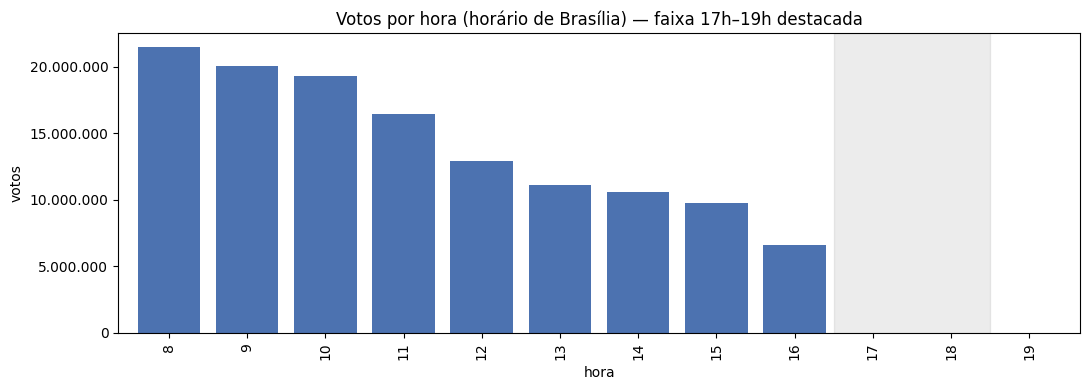

In [5]:
dist = log_hora.groupby("hora_brasilia")["votos"].sum()
dist.index = dist.index.astype(int)
ax = dist.plot.bar(figsize=(11, 4), width=0.8, color="#4C72B0")
pos = [i for i, h in enumerate(dist.index) if 17 <= h < 19]
if pos:
    ax.axvspan(min(pos) - 0.5, max(pos) + 0.5, color="grey", alpha=0.15)
ax.set(title="Votos por hora (horário de Brasília) — faixa 17h–19h destacada", xlabel="hora", ylabel="votos")
ax.yaxis.set_major_formatter(lambda v, _: fmt(v))
plt.tight_layout()

## 3 e 4. Votos sem biometria

Há duas medidas, e elas respondem perguntas diferentes:

| Medida | Fonte | Significado |
|---|---|---|
| **Votos sem habilitação biométrica** (resposta principal) | log da urna | Eleitores que votaram sem ser liberados pela própria digital: liberação pelo mesário com dados pessoais ou por código. Inclui quem **não tem biometria cadastrada**. |
| `QT_ELEI_BIOM_SEM_HABILITACAO` | Boletim de Urna (CSV) | Eleitores **com biometria cadastrada** que não foram habilitados por ela, por exemplo porque a digital não foi reconhecida. É um subconjunto da medida anterior. |

In [6]:
votos_bio = log_hora.votos_biometria.sum()
votos_sem_bio = votos_total - votos_bio
pct_sem_bio = pct(votos_sem_bio, votos_total)

### Boletim de Urna

No CSV do BU há uma linha por votável, e os campos da seção se repetem em cada uma. Por isso filtramos o cargo Presidente e deduplicamos por seção, com uma coluna de votos por candidato (`lula`, `flavio_bolsonaro`). O resultado fica em `dataset/processed/bu_secoes_presidente_t2.parquet`, versionado no repositório. Sem os CSVs do BU, o notebook usa esse parquet.

In [7]:
COLS_BU = ["SG_UF", "CD_MUNICIPIO", "NM_MUNICIPIO", "NR_ZONA", "NR_SECAO", "NR_LOCAL_VOTACAO", "DS_CARGO_PERGUNTA",
           "DS_TIPO_VOTAVEL", "NM_VOTAVEL", "QT_VOTOS", "QT_APTOS", "QT_COMPARECIMENTO", "QT_ELEI_BIOM_SEM_HABILITACAO"]
CHAVE_BU = ["SG_UF", "CD_MUNICIPIO", "NR_ZONA", "NR_SECAO"]


def bu_presidente():
    # Uma linha por seção: aptos, comparecimento, biometria sem habilitação, brancos, nulos e votos por candidato
    cache = PROCESSED_DIR / f"bu_secoes_presidente_t{TURNO}.parquet"
    arquivos = sorted(DATASET_DIR.glob(f"bweb_{TURNO}t_*/*.csv"))
    if not arquivos:
        if cache.exists():  # parquet versionado no repositório
            return pd.read_parquet(cache)
        raise FileNotFoundError("BU não encontrado — rode scripts/download.py e scripts/extract.py")
    if cache.exists() and cache.stat().st_mtime > max(a.stat().st_mtime for a in arquivos):
        return pd.read_parquet(cache)
    partes, atributos = [], []
    for arq in arquivos:
        for bloco in ler_csv(arq, usecols=COLS_BU, chunksize=2_000_000):
            bloco = bloco[bloco.DS_CARGO_PERGUNTA == "Presidente"]
            secao = bloco.groupby(CHAVE_BU)[["QT_APTOS", "QT_COMPARECIMENTO", "QT_ELEI_BIOM_SEM_HABILITACAO"]].max()
            tipos = bloco.pivot_table(index=CHAVE_BU, columns="DS_TIPO_VOTAVEL", values="QT_VOTOS", aggfunc="sum")
            nominais = bloco[bloco.DS_TIPO_VOTAVEL == "Nominal"]
            candidatos = nominais.pivot_table(index=CHAVE_BU, columns="NM_VOTAVEL", values="QT_VOTOS", aggfunc="sum")
            candidatos.columns = candidatos.columns.str.replace(" ", "_")
            partes.append(secao.join(tipos).join(candidatos))
            atributos.append(bloco.groupby(CHAVE_BU)[["NM_MUNICIPIO", "NR_LOCAL_VOTACAO"]].first())
    df = pd.concat(partes).groupby(level=CHAVE_BU).max().fillna(0).astype("int64")
    atrib = pd.concat(atributos).groupby(level=CHAVE_BU).first()
    df = atrib.join(df).reset_index()
    df.columns = [c.lower() for c in df.columns]
    df.to_parquet(cache, index=False)
    return df


bu = bu_presidente()
bu_comparecimento = bu.qt_comparecimento.sum()
bu_biom_sem_hab = bu.qt_elei_biom_sem_habilitacao.sum()
pct_bu_biom_sem_hab = pct(bu_biom_sem_hab, bu_comparecimento)

pd.DataFrame({
    "quantidade": [votos_total, votos_sem_bio, bu_comparecimento, bu_biom_sem_hab],
    "%": [100, pct_sem_bio, 100, pct_bu_biom_sem_hab],
}, index=["votos (log)", "votos sem habilitação biométrica (log)",
          "comparecimento (BU)", "biometria cadastrada sem habilitação (BU)"])

,quantidade,%
votos (log),128235225,100.000000
votos sem habilitação biométrica (log),16268923,12.686782
comparecimento (BU),128236074,100.000000
biometria cadastrada sem habilitação (BU),8632488,6.731716


### Por UF

In [8]:
uf_bio = log_hora.groupby("sg_uf")[["votos", "votos_biometria"]].sum()
uf_bio["votos_sem_biometria"] = uf_bio.votos - uf_bio.votos_biometria
uf_bio["%_sem_biometria"] = pct(uf_bio.votos_sem_biometria, uf_bio.votos)
uf_bu = bu.groupby("sg_uf")[["qt_comparecimento", "qt_elei_biom_sem_habilitacao"]].sum()
uf_bu["%_bu_biom_sem_habilitacao"] = pct(uf_bu.qt_elei_biom_sem_habilitacao, uf_bu.qt_comparecimento)
uf_bio.join(uf_bu).sort_values("%_sem_biometria", ascending=False)

,votos,votos_biometria,votos_sem_biometria,%_sem_biometria,qt_comparecimento,qt_elei_biom_sem_habilitacao,%_bu_biom_sem_habilitacao
sg_uf,,,,,,,
ZZ,380612,0,380612,100.000000,381443,0,0.000000
ES,2409518,1749945,659573,27.373649,2409214,151401,6.284249
MG,13044203,10653925,2390278,18.324446,13044203,887910,6.806932
RS,6889636,5747645,1141991,16.575491,6889638,582380,8.452984
RJ,10077449,8598858,1478591,14.672275,10077449,750301,7.445347
PE,6126467,5248521,877946,14.330380,6126467,399764,6.525196
SC,4762303,4151863,610440,12.818168,4762303,357632,7.509644
BA,9422033,8266863,1155170,12.260305,9422047,702255,7.453317
RN,2232823,1968073,264750,11.857187,2232823,180838,8.099075


## 5. Proporção dos votos: total e por estado

Fonte: `detalhe_votacao_munzona_2026_BR.csv`, com os totais oficiais. Neste turno, `QT_VOTOS` = válidos + brancos + nulos (+ anulados, *sub judice* e apurados em separado, quando existirem).

- **Comparecimento e abstenção:** percentual sobre os aptos.
- **Tipos de voto:** percentual sobre o total de votos.

Os votos por candidato vêm de `votacao_candidato_munzona_2026_BR.csv`.

Os dois CSVs, já filtrados para o 2º turno e Presidente, ficam em `dataset/processed/` (`munzona_presidente_t2.parquet` e `candidato_munzona_presidente_t2.parquet`), versionados no repositório. Sem os CSVs, o notebook usa esses parquets; se os CSVs forem baixados de novo, os parquets são regerados.

In [9]:
def ler_com_cache(csv, cache, **kw):
    # Lê o CSV do TSE (2º turno, Presidente) e grava o parquet; sem o CSV, usa o parquet versionado
    if csv.exists() and not (cache.exists() and cache.stat().st_mtime > csv.stat().st_mtime):
        df = ler_csv(csv, **kw)
        df = df[(df.NR_TURNO == TURNO) & (df.DS_CARGO == "Presidente")].reset_index(drop=True)
        df.to_parquet(cache, index=False)
        return df
    if cache.exists():
        return pd.read_parquet(cache)
    raise FileNotFoundError(f"{csv.name} não encontrado — rode scripts/download.py")


mz = ler_com_cache(DATASET_DIR / "detalhe_votacao_munzona_2026" / "detalhe_votacao_munzona_2026_BR.csv",
                   PROCESSED_DIR / f"munzona_presidente_t{TURNO}.parquet")
cand = ler_com_cache(DATASET_DIR / "votacao_candidato_munzona_2026" / "votacao_candidato_munzona_2026_BR.csv",
                     PROCESSED_DIR / f"candidato_munzona_presidente_t{TURNO}.parquet",
                     usecols=["NR_TURNO", "SG_UF", "DS_CARGO", "NR_CANDIDATO", "NM_URNA_CANDIDATO", "SG_PARTIDO",
                              "QT_VOTOS_NOMINAIS_VALIDOS"])
cand["candidato"] = cand.NM_URNA_CANDIDATO + " (" + cand.NR_CANDIDATO.astype(str) + " - " + cand.SG_PARTIDO + ")"

OUTROS = {
    "QT_VOTOS_BRANCOS": "brancos",
    "QT_VOTOS_NULOS": "nulos",
    "QT_VOTOS_NULOS_TECNICOS": "nulos técnicos",
    "QT_TOTAL_VOTOS_ANULADOS": "anulados",
    "QT_TOTAL_VOTOS_ANUL_SUBJUD": "anulados sub judice",
    "QT_VOTOS_ANULADOS_APU_SEP": "apurados em separado",
}


def composicao(por_uf=False):
    # Votos por candidato + demais tipos, em % do total de votos (soma = 100%)
    chave = ["SG_UF"] if por_uf else []
    votos_cand = (cand.groupby(chave + ["candidato"])["QT_VOTOS_NOMINAIS_VALIDOS"].sum()
                  .unstack("candidato") if por_uf else
                  cand.groupby("candidato")["QT_VOTOS_NOMINAIS_VALIDOS"].sum().to_frame("BRASIL").T)
    base = mz.groupby("SG_UF") if por_uf else mz.assign(SG_UF="BRASIL").groupby("SG_UF")
    soma = base[["QT_APTOS", "QT_COMPARECIMENTO", "QT_ABSTENCOES", "QT_VOTOS", *OUTROS]].sum()
    votos = votos_cand.join(soma[list(OUTROS)].rename(columns=OUTROS))
    votos = votos.loc[:, votos.sum() > 0]
    assert (votos.sum(axis=1) == soma.QT_VOTOS).all(), "candidatos + demais tipos deveria somar QT_VOTOS"
    tabela = pd.DataFrame({
        "aptos": soma.QT_APTOS,
        "comparecimento %": pct(soma.QT_COMPARECIMENTO, soma.QT_APTOS),
        "abstenção %": pct(soma.QT_ABSTENCOES, soma.QT_APTOS),
        "votos": soma.QT_VOTOS,
    })
    return tabela.join(votos.div(soma.QT_VOTOS, axis=0).mul(100).add_suffix(" %")).round(2), votos


comp_br, votos_br = composicao()
comp_br.T

SG_UF,BRASIL
aptos,1.587455e+08
comparecimento %,8.078000e+01
abstenção %,1.922000e+01
votos,1.282361e+08
FLAVIO BOLSONARO (22 - PL) %,4.665000e+01
LULA (13 - PT) %,5.011000e+01
brancos %,1.120000e+00
nulos %,2.120000e+00


In [10]:
comp_uf, votos_uf = composicao(por_uf=True)
comp_uf

,aptos,comparecimento %,abstenção %,votos,FLAVIO BOLSONARO (22 - PL) %,LULA (13 - PT) %,brancos %,nulos %
SG_UF,,,,,,,,
AC,613715,73.92,26.08,453654,63.42,31.86,1.11,3.62
AL,2442081,79.92,20.08,1951632,38.13,59.06,0.87,1.94
AM,2798661,78.33,21.67,2192059,44.49,52.27,0.84,2.40
AP,576910,74.53,25.47,429975,46.21,51.86,0.77,1.17
BA,11312891,83.29,16.71,9422047,27.69,68.83,0.98,2.50
CE,6996521,86.11,13.89,6024843,30.20,66.99,0.94,1.87
DF,2258995,82.70,17.30,1868280,52.43,44.17,1.20,2.20
ES,2991515,80.53,19.47,2409214,53.73,41.59,1.37,3.31
GO,5080385,79.66,20.34,4047280,57.95,39.18,1.07,1.81


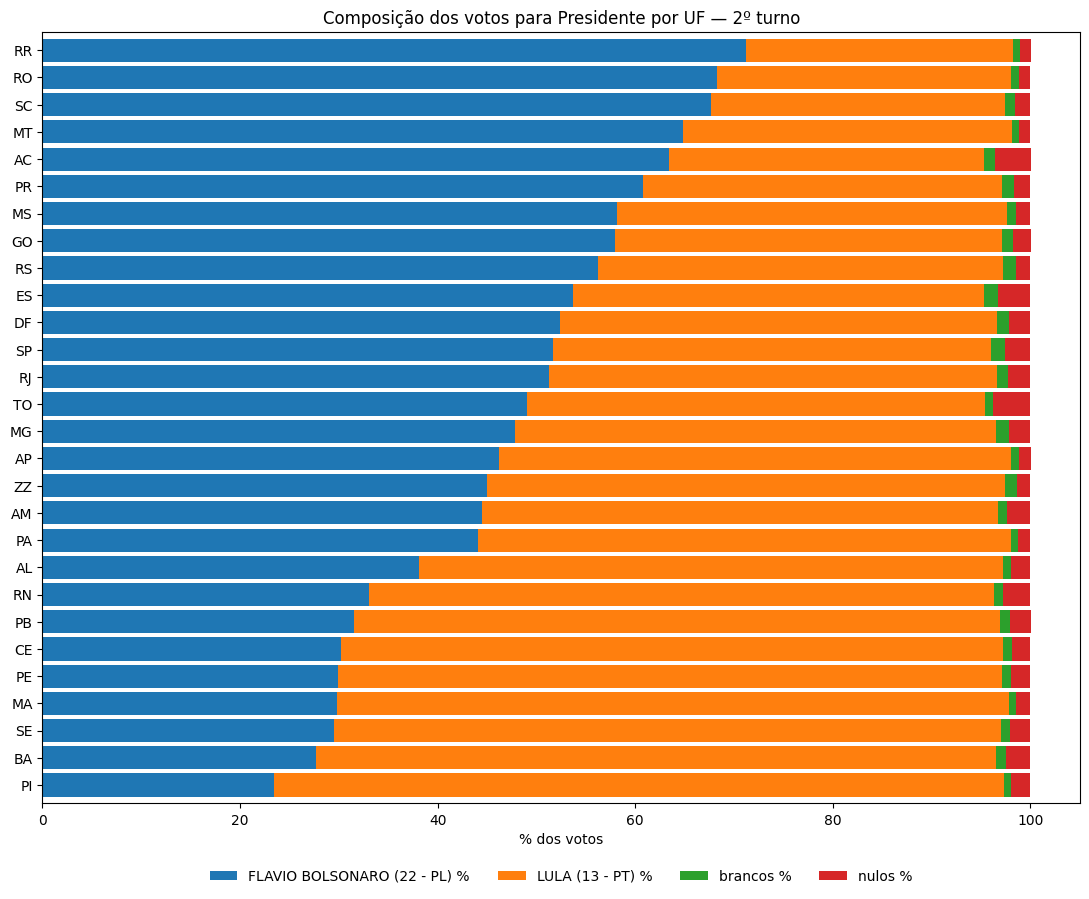

In [11]:
cols = [c for c in comp_uf.columns if c.endswith(" %") and c not in ("comparecimento %", "abstenção %")]
ax = comp_uf[cols].sort_values(cols[0]).plot.barh(stacked=True, figsize=(11, 9), width=0.85)
ax.set(title="Composição dos votos para Presidente por UF — 2º turno", xlabel="% dos votos", ylabel="")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.12), ncol=4, frameon=False)
plt.tight_layout()

### Lula × Flávio Bolsonaro: onde cada um teve seus votos

O voto é secreto. O RDV guarda os votos embaralhados, sem hora nem eleitor, e o log registra quem votou e quando, mas não em quem. Por isso não dá para saber **quem** votou em cada candidato, só **onde**: a menor unidade é a seção eleitoral (em média ~250 votos).

As tabelas abaixo usam o Boletim de Urna por seção (`bu`). A soma das seções confere com os totais de `votacao_candidato_munzona`.

In [12]:
CANDS = {"lula": "Lula", "flavio_bolsonaro": "Flávio Bolsonaro"}
REGIAO = {
    **dict.fromkeys(["AC", "AM", "AP", "PA", "RO", "RR", "TO"], "Norte"),
    **dict.fromkeys(["AL", "BA", "CE", "MA", "PB", "PE", "PI", "RN", "SE"], "Nordeste"),
    **dict.fromkeys(["DF", "GO", "MS", "MT"], "Centro-Oeste"),
    **dict.fromkeys(["ES", "MG", "RJ", "SP"], "Sudeste"),
    **dict.fromkeys(["PR", "RS", "SC"], "Sul"),
    "ZZ": "Exterior",
}
bu["regiao"] = bu.sg_uf.map(REGIAO)

oficial = cand.groupby("NM_URNA_CANDIDATO")["QT_VOTOS_NOMINAIS_VALIDOS"].sum()
for col in CANDS:
    nome = col.upper().replace("_", " ")
    assert bu[col].sum() == oficial[nome], f"BU por seção não confere com o total oficial de {nome}"


def lula_x_flavio(df, chave):
    t = df.groupby(chave)[list(CANDS)].sum().rename(columns=CANDS)
    validos = t.sum(axis=1)
    for c in CANDS.values():
        t[f"{c} % válidos"] = pct(t[c], validos).round(2)
    t["vantagem (votos)"] = t["Lula"] - t["Flávio Bolsonaro"]
    t["vencedor"] = np.select([t["vantagem (votos)"] > 0, t["vantagem (votos)"] < 0],
                              ["Lula", "Flávio Bolsonaro"], "empate")
    return t


lula_x_flavio(bu.assign(pais="BRASIL"), "pais")

,Lula,Flávio Bolsonaro,Lula % válidos,Flávio Bolsonaro % válidos,vantagem (votos),vencedor
pais,,,,,,
BRASIL,64256232,59826041,51.79,48.21,4430191,Lula


#### Por região

In [13]:
lula_x_flavio(bu, "regiao").sort_values("Lula % válidos", ascending=False)

,Lula,Flávio Bolsonaro,Lula % válidos,Flávio Bolsonaro % válidos,vantagem (votos),vencedor
regiao,,,,,,
Nordeste,24450432,10796736,69.37,30.63,13653696,Lula
Exterior,200154,171497,53.86,46.14,28657,Lula
Norte,5024626,5023547,50.01,49.99,1079,Lula
Sudeste,24037731,26844501,47.24,52.76,-2806770,Flávio Bolsonaro
Centro-Oeste,3733919,5603867,39.99,60.01,-1869948,Flávio Bolsonaro
Sul,6809370,11385893,37.42,62.58,-4576523,Flávio Bolsonaro


#### Por UF

In [14]:
lf_uf = lula_x_flavio(bu, "sg_uf").sort_values("Lula % válidos", ascending=False)
lf_uf

,Lula,Flávio Bolsonaro,Lula % válidos,Flávio Bolsonaro % válidos,vantagem (votos),vencedor
sg_uf,,,,,,
PI,1653989,525859,75.88,24.12,1128130,Lula
BA,6485258,2608761,71.31,28.69,3876497,Lula
MA,2808231,1229971,69.54,30.46,1578260,Lula
SE,989041,433354,69.53,30.47,555687,Lula
PE,4117513,1832554,69.20,30.80,2284959,Lula
CE,4036124,1819478,68.93,31.07,2216646,Lula
PB,1794059,865210,67.46,32.54,928849,Lula
RN,1413596,737409,65.72,34.28,676187,Lula
AL,1152621,744140,60.77,39.23,408481,Lula


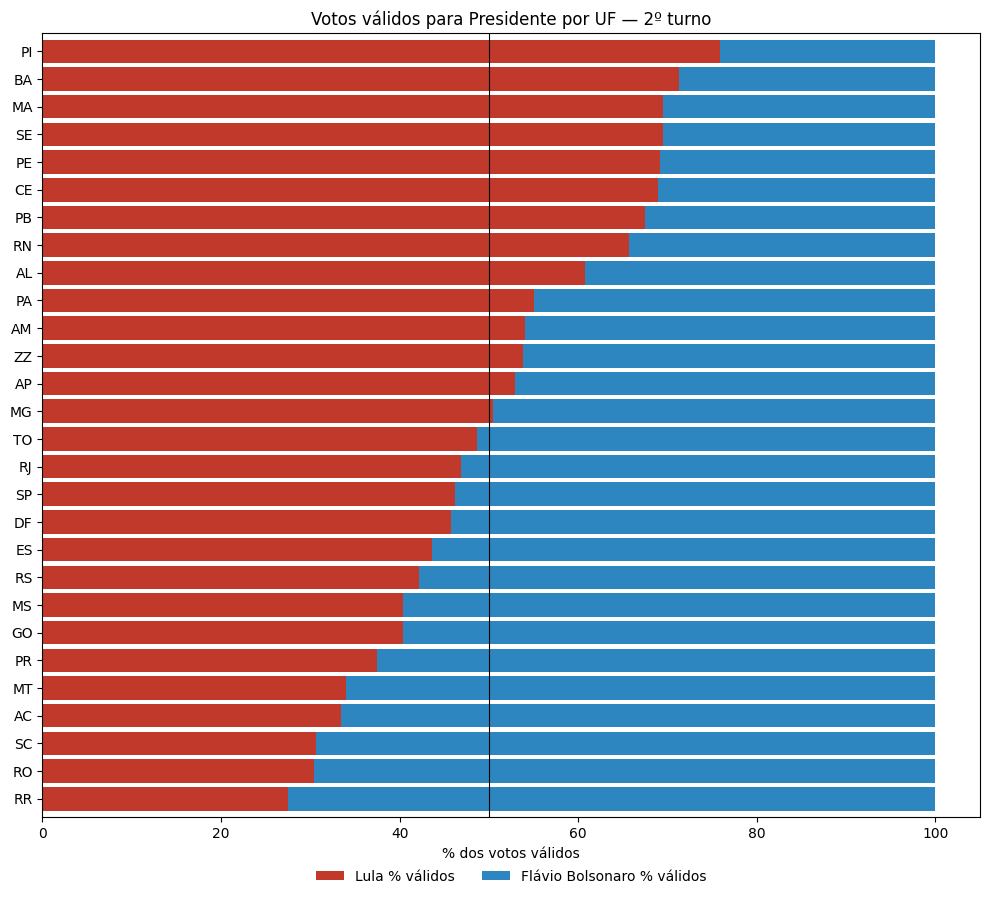

In [15]:
ax = lf_uf[["Lula % válidos", "Flávio Bolsonaro % válidos"]].iloc[::-1].plot.barh(
    stacked=True, figsize=(10, 9), width=0.85, color=["#C0392B", "#2E86C1"])
ax.axvline(50, color="black", lw=0.8)
ax.set(title="Votos válidos para Presidente por UF — 2º turno", xlabel="% dos votos válidos", ylabel="")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.1), ncol=2, frameon=False)
plt.tight_layout()

#### Por município

In [16]:
lf_mun = lula_x_flavio(bu, ["sg_uf", "cd_municipio", "nm_municipio"])
print("Municípios vencidos:", lf_mun.vencedor.value_counts().to_dict())
lf_mun.groupby(level="sg_uf").vencedor.value_counts().unstack(fill_value=0)

Municípios vencidos: {'Lula': 2963, 'Flávio Bolsonaro': 2751, 'empate': 1}


vencedor,Flávio Bolsonaro,Lula,empate
sg_uf,,,
AC,19,3,0
AL,9,93,0
AM,5,57,0
AP,2,14,0
BA,4,413,0
CE,0,184,0
DF,1,0,0
ES,60,18,0
GO,205,41,0


In [17]:
# Municípios com maior vantagem absoluta para cada candidato
pd.concat({
    "Lula": lf_mun.nlargest(10, "vantagem (votos)"),
    "Flávio Bolsonaro": lf_mun.nsmallest(10, "vantagem (votos)"),
})

Lula  Flávio Bolsonaro  Lula % válidos  Flávio Bolsonaro % válidos  vantagem (votos)          vencedor
                 sg_uf cd_municipio nm_municipio                                                                                                               
Lula             SP    71072        SÃO PAULO         3864354           3097923           55.50                       44.50            766431              Lula
                 BA    38490        SALVADOR          1154072            421752           73.24                       26.76            732320              Lula
                 CE    13897        FORTALEZA          932282            619634           60.07                       39.93            312648              Lula
                 PE    25313        RECIFE             633369            400342           61.27                       38.73            233027              Lula
                 PI    12190        TERESINA           337154            158802           67.98                       32.02            178352              Lula
                 MA    9210         SÃO LUÍS           385821            235947           62.05                       37.95            149874              Lula
                 RJ    60011        RIO DE JANEIRO    1898391           1785198           51.54                       48.46            113193              Lula
                 BA    35157        FEIRA DE SANTANA   234188            130891           64.15                       35.85            103297              Lula
                 RS    88013        PORTO ALEGRE       456019            360690           55.84                       44.16             95329              Lula
                 PA    4278         BELÉM              468891            383457           55.01                       44.99             85434              Lula
Flávio Bolsonaro PR    75353        CURITIBA           425092            702244           37.71                       62.29           -277152  Flávio Bolsonaro
                 GO    93734        GOIÂNIA            300757            504281           37.36                       62.64           -203524  Flávio Bolsonaro
                 SC    81795        JOINVILLE           94807            267371           26.18                       73.82           -172564  Flávio Bolsonaro
                 DF    97012        BRASÍLIA           825224            979542           45.72                       54.28           -154318  Flávio Bolsonaro
                 AM    2550         MANAUS             520418            657892           44.17                       55.83           -137474  Flávio Bolsonaro
                 PR    76678        LONDRINA            96869            217357           30.83                       69.17           -120488  Flávio Bolsonaro
                 MS    90514        CAMPO GRANDE       199121            312867           38.89                       61.11           -113746  Flávio Bolsonaro
                 SC    80470        BLUMENAU            57626            159139           26.58                       73.42           -101513  Flávio Bolsonaro
                 RR    3018         BOA VISTA           45675            142680           24.25                       75.75            -97005  Flávio Bolsonaro
                 RS    85995        CAXIAS DO SUL       92035            182748           33.49                       66.51            -90713  Flávio Bolsonaro

#### Por seção

Seções vencidas: {'Lula': 250935, 'Flávio Bolsonaro': 246115, 'empate': 2155}


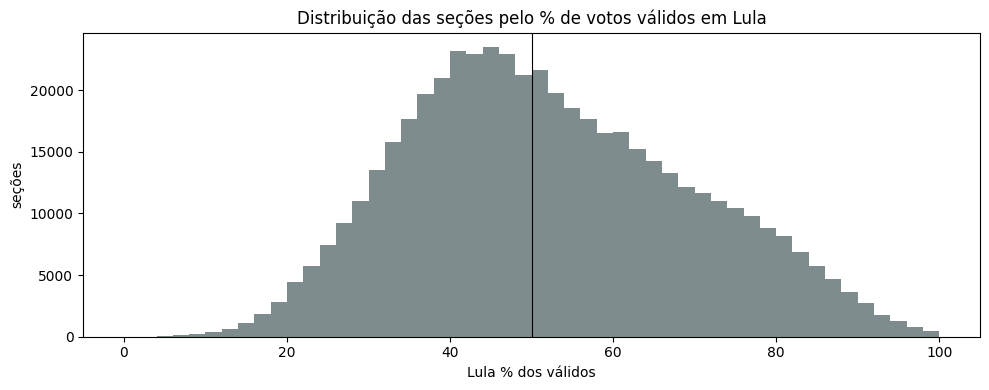

In [18]:
lf_secao = lula_x_flavio(bu, CHAVE_SECAO)
print("Seções vencidas:", lf_secao.vencedor.value_counts().to_dict())
ax = lf_secao["Lula % válidos"].plot.hist(bins=50, figsize=(10, 4), color="#7F8C8D")
ax.axvline(50, color="black", lw=0.8)
ax.set(title="Distribuição das seções pelo % de votos válidos em Lula", xlabel="Lula % dos válidos", ylabel="seções")
plt.tight_layout()

## 6. Ranking dos números digitados ao anular o voto

Os CSVs de resultado agregam todos os nulos como `NR_VOTAVEL = 96` ("VOTO NULO"). O número realmente digitado só aparece no **RDV** (Registro Digital do Voto), que guarda cada voto embaralhado e sem identificar o eleitor. O `process_urna.py` decodifica o RDV com a especificação ASN.1 do TSE (`scripts/spec/rdv.asn1`).

O ranking considera votos do tipo `nulo`: o eleitor digitou um número que não corresponde a nenhum candidato. Os `nuloAposSuspensao` (votação suspensa) não têm número digitado.

In [19]:
rdv_nulos = ler_parquets(f"rdv_nulos_t{TURNO}_*.parquet")
nulos_dig = rdv_nulos[rdv_nulos.tipo_voto == "nulo"]


def ranking_nulos(df, n=20):
    r = df.groupby("digitacao")["qt_votos"].sum().sort_values(ascending=False)
    out = r.head(n).to_frame("votos")
    out["% dos nulos"] = pct(out.votos, r.sum())
    out.index.name = "número digitado"
    out.insert(0, "posição", range(1, len(out) + 1))
    return out.round(2)


ranking = ranking_nulos(nulos_dig)
ranking

,posição,votos,% dos nulos
número digitado,,,
00,1,1483343,54.48
11,2,162324,5.96
14,3,143372,5.27
12,4,98490,3.62
99,5,78143,2.87
31,6,77823,2.86
15,7,77389,2.84
55,8,61750,2.27
10,9,38803,1.43


### Top 3 por UF

In [20]:
pd.concat({uf: ranking_nulos(g, n=3) for uf, g in nulos_dig.groupby("sg_uf")})

posição  votos  % dos nulos
   número digitado                             
AC 11                     1   7197        43.99
   10                     2   3287        20.09
   00                     3   2688        16.43
AL 00                     1  16118        42.54
   11                     2   3722         9.82
...                     ...    ...          ...
TO 00                     2   7991        22.35
   44                     3   6787        18.98
ZZ 00                     1   2595        50.71
   14                     2    484         9.46
   99                     3    389         7.60

[84 rows x 3 columns]

## Validação

Cruzamos, seção a seção, os dados lidos do log e do RDV com o Boletim de Urna oficial:

1. votos no log = `QT_COMPARECIMENTO` do BU;
2. brancos do RDV = votos `Branco` do BU para Presidente;
3. nulos do RDV (todos os tipos de nulo) = votos `Nulo` do BU para Presidente.

In [21]:
rdv_tipos = ler_parquets(f"rdv_tipos_t{TURNO}_*.parquet")
classe = np.select([rdv_tipos.tipo_voto.str.startswith("branco"), rdv_tipos.tipo_voto.str.startswith("nulo")],
                   ["rdv_brancos", "rdv_nulos"], "rdv_outros")
rdv_secao = rdv_tipos.assign(classe=classe).pivot_table(index=CHAVE_SECAO, columns="classe", values="qt_votos",
                                                         aggfunc="sum", fill_value=0)
log_secao = log_hora.groupby(CHAVE_SECAO)["votos"].sum()

val = bu.set_index(CHAVE_SECAO).join(log_secao, how="left").join(rdv_secao, how="left")
checagens = {
    "votos do log = comparecimento do BU": val.votos == val.qt_comparecimento,
    "brancos do RDV = brancos do BU": val.rdv_brancos == val.branco,
    "nulos do RDV = nulos do BU": val.rdv_nulos == val.nulo,
}
validacao = pd.DataFrame({
    "seções conferidas": {k: int(v.sum()) for k, v in checagens.items()},
    "% das seções do BU": {k: pct(v.sum(), len(val)) for k, v in checagens.items()},
})
print(f"Seções no BU: {fmt(len(val))}; sem log: {fmt(val.votos.isna().sum())}; sem RDV: {fmt(val.rdv_nulos.isna().sum())}")
print(f"Diferença total de votos (BU - log): {fmt(val.qt_comparecimento.sum() - val.votos.sum())}")
validacao.round(4)

Seções no BU: 499.205; sem log: 28; sem RDV: 0
Diferença total de votos (BU - log): 849


,seções conferidas,% das seções do BU
votos do log = comparecimento do BU,499170,99.993
brancos do RDV = brancos do BU,499205,100.000
nulos do RDV = nulos do BU,499205,100.000


In [22]:
# Seções divergentes (se houver)
val[~np.logical_and.reduce(list(checagens.values()))].head(20)

nm_municipio  nr_local_votacao  qt_aptos  qt_comparecimento  qt_elei_biom_sem_habilitacao  branco  nominal  nulo  flavio_bolsonaro  lula    regiao  \
sg_uf cd_municipio nr_zona nr_secao                                                                                                                                                                
BA    34711        21      178                       CONDE              1015       322                234                            15       2      231     1                83   148  Nordeste   
      35653        173     235                   IBOTIRAMA              1325       288                217                            33       1      216     0                76   140  Nordeste   
ES    57932        9       85        SANTA MARIA DE JETIBÁ              1031       371                308                            11       5      298     5               218    80   Sudeste   
MA    8893         47      609         SÃO JOSÉ DE RIBAMAR              2100       247                224                            19       2      219     3               115   104  Nordeste   
PB    21750        2       254                  SANTA RITA              1597       349                304                            34       1      296     7               127   169  Nordeste   
PI    11533        3       216                    PARNAÍBA              1260       297                259                            21       1      254     4                80   174  Nordeste   
RS    89060        17      191          BOA VISTA DO INCRA              1058        98                 92                            12       2       89     1                55    34       Sul   
SP    64777        395     298                   GUARULHOS              1260       350                268                            26       2      260     6               125   135   Sudeste   
ZZ    29173        1       494                    KATMANDU              1015        32                 13                             0       0       13     0                12     1  Exterior   
      29254        1       1                        ABIDJÃ              1015        91                 53                             0       0       53     0                22    31  Exterior   
      29270        1       3                         ACCRA              1015        43                 14                             0       1       13     0                 5     8  Exterior   
      29297        1       495                      ANCARA              1015        77                 39                             0       0       37     2                 8    29  Exterior   
      29300        1       6                         ARGEL              1015        48                 29                             0       3       26     0                 3    23  Exterior   
      29394        1       28                       BISSAU              1015        88                 41                             0       0       41     0                22    19  Exterior   
      29580        1       96                   CONCEPCIÓN              1015        78                 31                             0       0       31     0                28     3  Exterior   
      29645        1       380                        DÍLI              1015        89                 52                             0       1       51     0                33    18  Exterior   
      29750        1       1703                      HANÓI              1015        82                 34                             0       0       32     2                17    15  Exterior   
      29777        1       127                      HAVANA              1015        92                 45                             0       1       44     0                 1    43  Exterior   
      29858        1       1183                       KIEV              1015        65                 21                     

## Base consolidada por seção

Junta, em uma linha por seção, o Boletim de Urna (votos por candidato, brancos, nulos, aptos, comparecimento), as medidas do log (votos das 17h às 19h de Brasília, votos sem habilitação biométrica) e os totais do RDV. O arquivo `dataset/processed/secoes_presidente_t2.parquet` permite novas análises sem baixar nada de novo, por exemplo cruzar o voto por candidato com a votação tardia ou com a falta de biometria (sempre no nível da seção, nunca do eleitor).

In [23]:
log_secao_medidas = (log_hora.assign(votos_17h_19h=log_hora.votos.where(na_janela, 0),
                                     votos_sem_biometria=log_hora.votos - log_hora.votos_biometria)
                     .groupby(CHAVE_SECAO)[["votos", "votos_17h_19h", "votos_sem_biometria"]].sum()
                     .rename(columns={"votos": "votos_log"}))
secoes = (bu.set_index(CHAVE_SECAO)
          .join(log_secao_medidas, how="left")
          .join(rdv_secao, how="left")
          .join(desloc_mun.set_index(["sg_uf", "cd_municipio"]), on=["sg_uf", "cd_municipio"])
          .reset_index())
secoes.to_parquet(PROCESSED_DIR / f"secoes_presidente_t{TURNO}.parquet", index=False)
print(f"{fmt(len(secoes))} seções, {secoes.shape[1]} colunas")
secoes.dtypes.to_frame("tipo").T

499.205 seções, 22 colunas


,sg_uf,cd_municipio,nr_zona,nr_secao,nm_municipio,nr_local_votacao,qt_aptos,qt_comparecimento,qt_elei_biom_sem_habilitacao,branco,nominal,nulo,flavio_bolsonaro,lula,regiao,votos_log,votos_17h_19h,votos_sem_biometria,rdv_brancos,rdv_nulos,rdv_outros,desloc_brasilia
tipo,object,int64,int64,int64,object,int64,int64,int64,int64,int64,int64,int64,int64,int64,object,float64,float64,float64,int64,int64,int64,float64


## Estimativas: em quem votou quem votou depois das 17h ou sem biometria?

**Não é possível contar isso.** O sistema da urna foi feito para impedir esse cruzamento:

- o **log** registra cada eleitor (a hora e se foi habilitado por biometria), mas não em quem votou;
- o **RDV** registra cada voto, mas embaralhado, sem hora, sem ordem e sem ligação com o eleitor.

Nenhum campo liga uma linha do log a um voto do RDV; se ligasse, o voto não seria secreto. A menor unidade em que voto e horário ou biometria aparecem juntos é a **seção** (~250 eleitores). O que dá para fazer é **inferência ecológica**, ou seja, estimar o comportamento de um grupo a partir de agregados. Ela tem limites conhecidos (a *falácia ecológica*).

Usamos dois métodos, nas seções do Brasil (sem o exterior) cujo log confere com o comparecimento do BU:

1. **Perfil das seções:** média do resultado das seções, ponderada pelo número de eleitores do grupo em cada uma. Responde "como votaram as seções onde estavam esses eleitores", e não "como votaram esses eleitores". Se o grupo votasse igual aos vizinhos de seção, as duas respostas coincidiriam.
2. **Regressão dentro do município** (regressão de Goodman com efeito fixo de município): para cada opção de voto, regride a sua fração na seção contra a fração de eleitores do grupo na seção, comparando só seções do mesmo município. O valor previsto para uma seção com 100% do grupo é a estimativa. Ela supõe que, dentro do município, o grupo vota igual em todas as seções. Não há garantia disso, e o resultado pode sair fora de 0–100%, sinal de que a suposição falhou.

In [24]:
OPCOES = {"lula": "Lula", "flavio_bolsonaro": "Flávio Bolsonaro", "branco": "brancos", "nulo": "nulos"}
GRUPOS = {"votos_17h_19h": "depois das 17h (Brasília)", "votos_sem_biometria": "sem biometria"}

est = secoes[(secoes.sg_uf != "ZZ") & (secoes.qt_comparecimento > 0) & (secoes.votos_log == secoes.qt_comparecimento)]
peso = est.qt_comparecimento
frac_votos = est[list(OPCOES)].div(peso, axis=0)
municipio = [est.sg_uf, est.cd_municipio]


def perfil_secoes(grupo):
    w = est[grupo]
    return frac_votos.mul(w, axis=0).sum() / w.sum() * 100


def regressao_municipio(grupo):
    x = est[grupo] / peso
    xd = x - x.groupby(municipio).transform("mean")
    res = {}
    for op in OPCOES:
        y = frac_votos[op]
        yd = y - y.groupby(municipio).transform("mean")
        b = np.average(xd * yd, weights=peso) / np.average(xd * xd, weights=peso)
        a = np.average(y, weights=peso) - b * np.average(x, weights=peso)
        res[op] = 100 * (a + b)  # previsão para uma seção com 100% do grupo
    return pd.Series(res)


geral = frac_votos.mul(peso, axis=0).sum() / peso.sum() * 100
linhas = {("todos os eleitores", "resultado contado"): geral}
for g, nome in GRUPOS.items():
    linhas[(nome, "perfil das seções")] = perfil_secoes(g)
    linhas[(nome, "regressão dentro do município")] = regressao_municipio(g)
estimativas = pd.DataFrame(linhas).T.rename(columns=OPCOES).round(1)
estimativas.insert(0, "eleitores", [int(peso.sum())] + [int(est[g].sum()) for g in GRUPOS for _ in range(2)])
print(f"Seções usadas: {fmt(len(est))} de {fmt(len(secoes))}")
estimativas

Seções usadas: 497.889 de 499.205


eleitores   Lula  Flávio Bolsonaro  brancos  nulos
todos os eleitores        resultado contado              127852725   50.1              46.7      1.1    2.1
depois das 17h (Brasília) perfil das seções                  34319   52.5              44.0      1.2    2.3
                          regressão dentro do município      34319  159.2             -71.9      8.6    4.2
sem biometria             perfil das seções               15887646   50.5              46.2      1.1    2.1
                          regressão dentro do município   15887646   52.7              44.2      1.1    2.0

In [25]:
# Quantos eleitores do grupo há por seção: com muito poucos, não há variação suficiente para a regressão
pd.DataFrame({nome: {
    "eleitores do grupo": fmt(est[g].sum()),
    "% dos votos": fmt_pct(pct(est[g].sum(), peso.sum()), 3),
    "média por seção": f"{est[g].mean():.2f}",
    "seções com nenhum": fmt_pct(pct((est[g] == 0).sum(), len(est))),
} for g, nome in GRUPOS.items()})

,depois das 17h (Brasília),sem biometria
eleitores do grupo,34.319,15.887.646
% dos votos,"0,027%","12,427%"
média por seção,0.07,31.91
seções com nenhum,"94,00%","0,03%"


### Como ler

- **Sem biometria:** são ~16 milhões de eleitores, ~12% dos votos, presentes em quase todas as seções. Os dois métodos dão resultados coerentes entre si e dentro de 0–100%. Indicam um grupo levemente mais favorável a Lula que a média. Ainda assim é uma **estimativa**, não uma contagem.
- **Depois das 17h:** são poucos eleitores, ~0,03% dos votos e menos de 1 por seção em média, e a maioria das seções não tem nenhum. Com tão pouca variação, a regressão não separa o efeito desses eleitores das outras diferenças entre seções e devolve **valores impossíveis** (acima de 100% ou negativos). Por isso **não há estimativa confiável** do voto de quem votou depois das 17h. O perfil das seções continua válido, mas só descreve **onde** essas pessoas votaram.

## Resumo

In [26]:
br = comp_br.iloc[0]
cands = sorted([f"{c} %" for c in cand.candidato.unique() if f"{c} %" in br.index], key=lambda c: -br[c])
uf_nulo_max = comp_uf["nulos %"].idxmax()
uf_bio_max = uf_bio.drop(index="ZZ", errors="ignore")["%_sem_biometria"].idxmax()  # no exterior não há habilitação biométrica
top5 = ", ".join(f"**{d}** ({fmt(v)})" for d, v in ranking.votos.head(5).items())
sem_log = int(val.votos.isna().sum())
diverg_log = int((val.votos.notna() & (val.votos != val.qt_comparecimento)).sum())
dif_votos = int(val.qt_comparecimento.sum() - val.votos.sum())

sb = estimativas.loc[("sem biometria", "regressão dentro do município")]
tarde = estimativas.loc[("depois das 17h (Brasília)", "perfil das seções")]
lf_br = lula_x_flavio(bu.assign(pais="BRASIL"), "pais").iloc[0]
ufs_lula, ufs_flavio = [(lf_uf.drop(index="ZZ").vencedor == c).sum() for c in CANDS.values()]
mun_lula, mun_flavio = [(lf_mun.drop(index="ZZ", level="sg_uf").vencedor == c).sum() for c in CANDS.values()]  # sem as cidades do exterior
sec_lula, sec_flavio = [(lf_secao.vencedor == c).sum() for c in CANDS.values()]
linhas_cand = "\n".join(f"   - {c.removesuffix(' %')}: {fmt_pct(br[c])}" for c in cands)
texto = f'''
**2º turno para Presidente, 25/10/2026**

1. **Quantas pessoas votaram entre 17h e 19h?** {fmt(votos_17_19)} pessoas (horário de Brasília).
2. **Proporção dos votos de 17h até 19h:** {fmt_pct(pct_17_19, 3)} dos {fmt(votos_total)} votos.
3. **Quantas pessoas votaram sem biometria?** {fmt(votos_sem_bio)} pessoas foram liberadas para votar sem
   reconhecimento da própria digital. Dessas, {fmt(bu_biom_sem_hab)} tinham biometria cadastrada e não foram
   reconhecidas, segundo o Boletim de Urna.
4. **Proporção dos votos sem biometria:** {fmt_pct(pct_sem_bio)} dos votos. Só considerando quem tinha biometria
   cadastrada e não foi reconhecido: {fmt_pct(pct_bu_biom_sem_hab)}. Entre as UFs, a maior proporção sem biometria
   está em {uf_bio_max} ({fmt_pct(uf_bio.loc[uf_bio_max, "%_sem_biometria"])}). No exterior não há habilitação biométrica.
5. **Proporção dos votos (Brasil):** comparecimento de {fmt_pct(br["comparecimento %"])} dos aptos e
   abstenção de {fmt_pct(br["abstenção %"])}. Em % do total de votos:
{linhas_cand}
   - brancos: {fmt_pct(br["brancos %"])}
   - nulos: {fmt_pct(br["nulos %"])}

   Nos votos válidos: Lula {fmt(lf_br["Lula"])} ({fmt_pct(lf_br["Lula % válidos"])}) e Flávio Bolsonaro
   {fmt(lf_br["Flávio Bolsonaro"])} ({fmt_pct(lf_br["Flávio Bolsonaro % válidos"])}). Lula venceu em {ufs_lula} UFs,
   {fmt(mun_lula)} municípios e {fmt(sec_lula)} seções; Flávio, em {ufs_flavio} UFs, {fmt(mun_flavio)} municípios
   e {fmt(sec_flavio)} seções. A tabela por estado está na seção 5. O maior percentual de nulos foi em {uf_nulo_max} ({fmt_pct(comp_uf.loc[uf_nulo_max, "nulos %"])}).
6. **Números mais digitados para anular o voto:** {top5}.

**Em quem votou quem votou depois das 17h ou sem biometria?** Não dá para contar: o voto é secreto, e log e RDV não se
ligam. Estimativa estatística (seção "Estimativas"): eleitores sem biometria, cerca de {fmt_pct(sb["Lula"], 1)} Lula,
{fmt_pct(sb["Flávio Bolsonaro"], 1)} Flávio, {fmt_pct(sb["brancos"], 1)} brancos e {fmt_pct(sb["nulos"], 1)} nulos. Para quem votou
depois das 17h não há estimativa confiável. As seções onde essas pessoas votaram deram {fmt_pct(tarde["Lula"], 1)} a Lula e
{fmt_pct(tarde["Flávio Bolsonaro"], 1)} a Flávio, mas isso descreve o lugar, não o voto delas.

*Ressalvas:*
- Horários convertidos para Brasília a partir da hora local de cada urna. O exterior (ZZ) usa a hora local de cada país.
- Validação contra o Boletim de Urna, seção a seção:
  - brancos e nulos do RDV conferem em {fmt_pct(validacao.iloc[2, 1], 3)} das seções;
  - votos do log conferem com o comparecimento em {fmt_pct(validacao.iloc[0, 1], 3)}. Ficaram de fora {sem_log} seções sem log e
    {diverg_log} divergentes, uma diferença de {fmt(abs(dif_votos))} votos no total.
'''
display(Markdown(texto))


**2º turno para Presidente, 25/10/2026**

1. **Quantas pessoas votaram entre 17h e 19h?** 34.736 pessoas (horário de Brasília).
2. **Proporção dos votos de 17h até 19h:** 0,027% dos 128.235.225 votos.
3. **Quantas pessoas votaram sem biometria?** 16.268.923 pessoas foram liberadas para votar sem
   reconhecimento da própria digital. Dessas, 8.632.488 tinham biometria cadastrada e não foram
   reconhecidas, segundo o Boletim de Urna.
4. **Proporção dos votos sem biometria:** 12,69% dos votos. Só considerando quem tinha biometria
   cadastrada e não foi reconhecido: 6,73%. Entre as UFs, a maior proporção sem biometria
   está em ES (27,37%). No exterior não há habilitação biométrica.
5. **Proporção dos votos (Brasil):** comparecimento de 80,78% dos aptos e
   abstenção de 19,22%. Em % do total de votos:
   - LULA (13 - PT): 50,11%
   - FLAVIO BOLSONARO (22 - PL): 46,65%
   - brancos: 1,12%
   - nulos: 2,12%

   Nos votos válidos: Lula 64.256.232 (51,79%) e Flávio Bolsonaro
   59.826.041 (48,21%). Lula venceu em 13 UFs,
   2.875 municípios e 250.935 seções; Flávio, em 14 UFs, 2.695 municípios
   e 246.115 seções. A tabela por estado está na seção 5. O maior percentual de nulos foi em TO (3,75%).
6. **Números mais digitados para anular o voto:** **00** (1.483.343), **11** (162.324), **14** (143.372), **12** (98.490), **99** (78.143).

**Em quem votou quem votou depois das 17h ou sem biometria?** Não dá para contar: o voto é secreto, e log e RDV não se
ligam. Estimativa estatística (seção "Estimativas"): eleitores sem biometria, cerca de 52,7% Lula,
44,2% Flávio, 1,1% brancos e 2,0% nulos. Para quem votou
depois das 17h não há estimativa confiável. As seções onde essas pessoas votaram deram 52,5% a Lula e
44,0% a Flávio, mas isso descreve o lugar, não o voto delas.

*Ressalvas:*
- Horários convertidos para Brasília a partir da hora local de cada urna. O exterior (ZZ) usa a hora local de cada país.
- Validação contra o Boletim de Urna, seção a seção:
  - brancos e nulos do RDV conferem em 100,000% das seções;
  - votos do log conferem com o comparecimento em 99,993%. Ficaram de fora 28 seções sem log e
    7 divergentes, uma diferença de 849 votos no total.
